# Prognos av trafikträngsel 60 minuter fram

**Data:** NordCauc Urban Mobility Intelligence 2023–2025 (Kaggle), filen `traffic_flow_sensors.csv`. Mätningar från trafiksensorer i nordiska städer och Baku.

**Problem:** Kan vi förutsäga trängselnivån vid en sensor **60 minuter framåt i tiden**?

| Nivå | Betydelse |
|---|---|
| free_flow | fritt flöde |
| light | lätt trängsel |
| moderate | måttlig trängsel |
| heavy | kraftig trängsel / kö |

**Varför:** En trafikledare eller pendlare vill veta hur det *blir*, inte bara hur det *är*. En människa kan redan gissa ganska bra: "om en timme är det som nu". Målet är att undersöka om maskininlärning kan göra en bättre gissning än människan, och hur valet av algoritm och optimeringar påverkar resultatet.

## Beslutslogg
Här dokumenterar vi besluten under arbetets gång och varför de togs.

| # | Beslut | Varför |
|---|---|---|
| 1 | Valde datasetet NordCauc Urban Mobility | Nytt dataset för gruppen, många rader, enkelt att få ut vettig data?|
| 2 | Först: förutsäga trängsel *nu* | Enkelt första problem |
| 3 | Ändrade till: förutsäga trängsel *om 60 minuter* | Trängseln *nu* gick nästan att läsa av direkt från hastighet och beläggning. |

In [1]:
import os
import kagglehub
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

levels = ['free_flow', 'light', 'moderate', 'heavy']

/Users/carolineluther/Downloads/mu25-ml-group-2-main/.pixi/envs/default/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Läsa in data

In [2]:
path = kagglehub.dataset_download("olaflundstrom/nordcauc-urban-mobility-intelligence")
print(os.listdir(path))

['public_transit_ridership.csv', 'traffic_flow_sensors.csv', 'micromobility_trips.csv', 'pedestrian_flow_counters.csv']


In [3]:
df = pd.read_csv(os.path.join(path, 'traffic_flow_sensors.csv'))
df.shape

(200000, 30)

## Målet: trafiken 60 minuter fram
**Problem:** Vi vill förutsäga trafikklassen 60 minuter framåt, utifrån vad vi vet nu.

**Hur:** Vi sorterar mätningarna per sensor i tidsordning. För varje mätning hämtar vi trafikklassen från samma sensors nästa mätning (`groupby('sensor_id')` och `shift(-1)`), och behåller bara rader där nästa mätning är exakt 60 minuter senare. Kolumnen heter `future_congestion_level`.

**Varför sortering:** `shift(-1)` tar raden under. Utan sortering är raden under inte nödvändigtvis sensorns nästa mätning i tid.

In [4]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(by=['sensor_id', 'timestamp'])

df['future_congestion_level'] = df.groupby('sensor_id')['congestion_level'].shift(-1)
df['next_timestamp'] = df.groupby('sensor_id')['timestamp'].shift(-1)
df['duration_to_next'] = df['next_timestamp'] - df['timestamp']

df = df[df['duration_to_next'] == pd.Timedelta(minutes=60)]
print(len(df), 'av 200 000 rader har en mätning exakt 60 minuter senare')

2270 av 200 000 rader har en mätning exakt 60 minuter senare


**Resultat:** Bara ca 1 % av raderna har en mätning från samma sensor exakt en timme senare, eftersom mätningarna ligger glest.

In [5]:
df.head()

,sensor_id,city,country,district,timestamp,date,hour,day_of_week,is_weekend,is_public_holiday,...,precipitation_mm,weather_condition,incident_type,ai_predicted_volume,ai_predicted_congestion,ai_model_version,data_quality_flag,future_congestion_level,next_timestamp,duration_to_next
165398,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2023-08-18 07:30:00,2023-08-18,7,Friday,False,False,...,0.0,clear,none,426,light,CityPulse-XGB,good,heavy,2023-08-18 08:30:00,0 days 01:00:00
165477,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2023-10-08 12:15:00,2023-10-08,12,Sunday,True,False,...,0.1,drizzle,none,889,heavy,CityPulse-XGB,good,heavy,2023-10-08 13:15:00,0 days 01:00:00
165495,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2023-10-24 17:45:00,2023-10-24,17,Tuesday,False,False,...,0.2,light_rain,none,990,heavy,CityPulse-XGB,good,heavy,2023-10-24 18:45:00,0 days 01:00:00
165528,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2023-11-23 18:30:00,2023-11-23,18,Thursday,False,True,...,0.0,partly_cloudy,none,740,moderate,CityPulse-XGB,missing_partial,light,2023-11-23 19:30:00,0 days 01:00:00
165683,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2024-04-19 05:00:00,2024-04-19,5,Friday,False,False,...,0.3,light_rain,none,111,free_flow,CityPulse-XGB,missing_partial,free_flow,2024-04-19 06:00:00,0 days 01:00:00


In [6]:
df['future_congestion_level'].value_counts(normalize=True)

future_congestion_level
free_flow    0.473128
moderate     0.182819
light        0.178414
heavy        0.165639
Name: proportion, dtype: float64

## Val av kolumner
Datasetet har 30 kolumner. Vi behåller 17 som beskriver trafiksituationen nu (tid på dygnet, vägtyp, trafikmått, väder, incidenter), samt målet `future_congestion_level`.

Vi tar bort: 
- sensor-id och plats (sensor_id, city, country, district, latitude, longitude) 
- exakt tidpunkt (timestamp, date), 
- färdiga AI-prognoser (ai_predicted_volume, ai_predicted_congestion, ai_model_version)
- data_quality_flag. 
- ev_count_15min (antal elbilar).

**Varför:** En modell som ska gälla för alla sensorer ska inte lära sig utantill vilken sensor eller stad en rad kommer från, och de färdiga prognoserna är någon annans gissning som skulle dölja vad vår egen modell lär sig.

Nuvarande trafikklass (congestion_level) och hastighet behålls, eftersom vi känner till dem när vi gissar 60 minuter fram.

In [7]:
kolumner = [
    'hour', 'day_of_week', 'is_weekend', 'is_public_holiday', 'season',
    'road_type', 'speed_limit_kmh', 'lane_count', 'vehicle_count_15min',
    'avg_speed_kmh', 'congestion_level', 'occupancy_rate', 'truck_count_15min',
    'temperature_c', 'precipitation_mm', 'weather_condition', 'incident_type', 'future_congestion_level'
]
df = df[kolumner].dropna()
df.isna().sum().sum()

np.int64(0)

In [8]:
df.info()

<class 'pandas.DataFrame'>
Index: 2270 entries, 165398 to 11130
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hour                     2270 non-null   int64  
 1   day_of_week              2270 non-null   str    
 2   is_weekend               2270 non-null   bool   
 3   is_public_holiday        2270 non-null   bool   
 4   season                   2270 non-null   str    
 5   road_type                2270 non-null   str    
 6   speed_limit_kmh          2270 non-null   int64  
 7   lane_count               2270 non-null   int64  
 8   vehicle_count_15min      2270 non-null   int64  
 9   avg_speed_kmh            2270 non-null   float64
 10  congestion_level         2270 non-null   str    
 11  occupancy_rate           2270 non-null   float64
 12  truck_count_15min        2270 non-null   int64  
 13  temperature_c            2270 non-null   float64
 14  precipitation_mm         2270 non-

In [9]:
df.describe()

,hour,speed_limit_kmh,lane_count,vehicle_count_15min,avg_speed_kmh,occupancy_rate,truck_count_15min,temperature_c,precipitation_mm
count,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000
mean,11.337445,64.581498,2.631718,266.488106,53.467225,0.251278,9.396035,16.279956,0.512159
std,6.865628,22.445786,0.982912,324.686855,22.881421,0.196372,11.356147,12.456725,1.174506
min,0.000000,30.000000,1.000000,9.000000,6.300000,0.031000,0.000000,-6.800000,0.000000
25%,6.000000,50.000000,2.000000,60.000000,37.100000,0.071000,2.000000,6.100000,0.000000
50%,11.000000,60.000000,2.000000,159.000000,49.750000,0.237000,6.000000,16.150000,0.000000
75%,17.000000,80.000000,3.000000,317.000000,67.400000,0.379750,12.000000,28.300000,0.500000
max,23.000000,130.000000,5.000000,2685.000000,131.300000,0.703000,83.000000,39.100000,11.600000


## Antal fordon per 15 minuter
**Fråga:** Hur är antalet fordon (vehicle_count_15min) fördelat?

**Varför:** Vi vill lära känna datan och kontrollera att den ser rimlig ut innan vi tränar en modell.

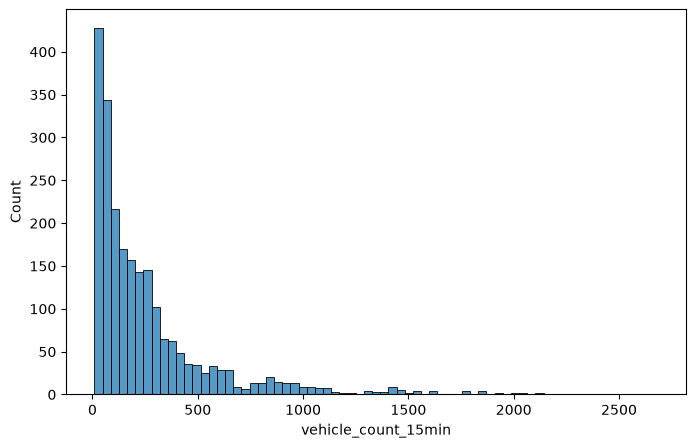

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='vehicle_count_15min')
plt.show()

**Resultat:** De flesta mätningar har få fordon, och några få har mycket högre värden. Fördelningen är alltså skev åt höger. Därför är medianen en bättre bild av ett typiskt värde än medelvärdet, som dras upp av de extrema värdena.

## Fördelning av målvariabeln
**Fråga:** Är de fyra trafikklasserna (free_flow, light, moderate, heavy) jämnt fördelade, eller är någon klass mycket vanligare?

**Varför:** Om en klass dominerar kan en modell få hög accuracy genom att alltid gissa den klassen. Då behöver vi veta vad en enkel gissning ger för att kunna bedöma om modellen faktiskt lär sig något.

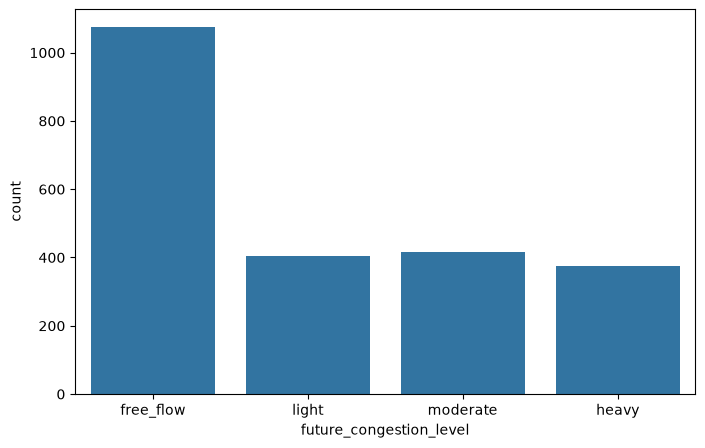

In [11]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='future_congestion_level', order=levels)
plt.show()

In [12]:
df['future_congestion_level'].value_counts(normalize=True)

future_congestion_level
free_flow    0.473128
moderate     0.182819
light        0.178414
heavy        0.165639
Name: proportion, dtype: float64

**Resultat:** free_flow är vanligast (47,3 %) och heavy minst (16,6 %). Att alltid gissa free_flow ger alltså 47,3 % rätt, och det är vår baslinje. En modell måste slå 47,3 % på testdatan för att visa att den har lärt sig något.

## Trafikbelastning per timme
**Fråga:** Varierar trafikklassen 60 minuter fram (future_congestion_level) beroende på tid på dygnet?

**Varför:** Timmen är känd i förväg, så den kan användas för att förutsäga framtida trafik. Om heavy är vanligare vid vissa timmar (t.ex. rusningstid) separerar hour klasserna och är en användbar feature.

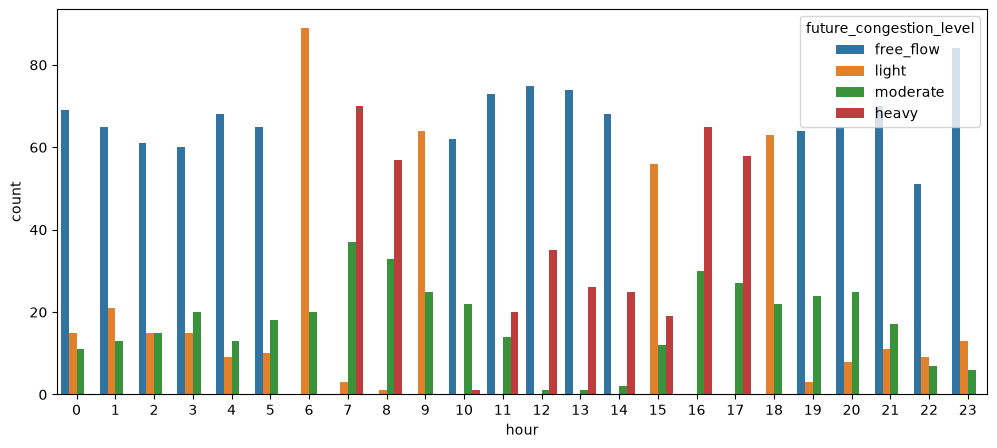

In [13]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='hour', hue='future_congestion_level', hue_order=levels)
plt.show()

**Resultat:** Heavy är vanligast kl. 7–8 och 16–17, en timme före själva rusningstiden, eftersom hour är klockslaget för mätningen men trafikklassen gäller 60 minuter senare.

Light är vanligast strax före och efter topparna (kl. 6, 9, 15 och 18). Free_flow är vanligast nattetid (0–5), mitt på dagen (10–14) och sent på kvällen (19–23).

Klasserna fördelas alltså tydligt olika över dygnet, så hour separerar klasserna väl. Det gör hour till en användbar feature, och eftersom timmen är känd i förväg kan den användas för att förutsäga framtida trafik.

## Trafikbelastning per väder
**Fråga:** Påverkar vädret (weather_condition) vilken trafikklass vi får?

**Varför:** Väder är något vi kan känna till i förväg (t.ex. via väderprognos), så det kan användas för att förutsäga framtida trafik. Om fördelningen av trafikklasser skiljer sig mellan väderförhållanden separerar vädret klasserna och är en användbar feature.

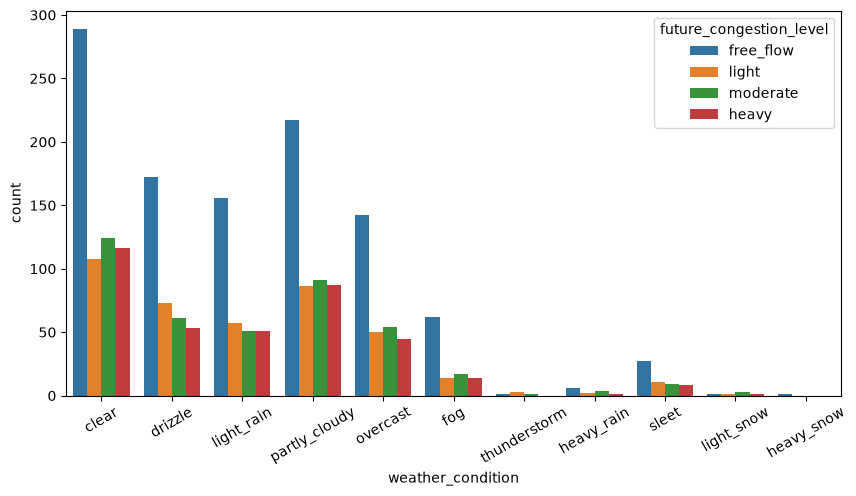

In [14]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='weather_condition', hue='future_congestion_level', hue_order=levels)
plt.xticks(rotation=30)
plt.show()

In [15]:
df.groupby('weather_condition')['future_congestion_level'].value_counts(normalize=True)

weather_condition  future_congestion_level
clear              free_flow                  0.453689
                   moderate                   0.194662
                   heavy                      0.182104
                   light                      0.169545
drizzle            free_flow                  0.479109
                   light                      0.203343
                   moderate                   0.169916
                   heavy                      0.147632
fog                free_flow                  0.579439
                   moderate                   0.158879
                   light                      0.130841
                   heavy                      0.130841
heavy_rain         free_flow                  0.461538
                   moderate                   0.307692
                   light                      0.153846
                   heavy                      0.076923
heavy_snow         free_flow                  1.000000
light_rain         fre

In [16]:
df['weather_condition'].value_counts()

weather_condition
clear            637
partly_cloudy    481
drizzle          359
light_rain       315
overcast         291
fog              107
sleet             55
heavy_rain        13
light_snow         6
thunderstorm       5
heavy_snow         1
Name: count, dtype: int64

**Resultat:** De flesta väder har ungefär samma fördelning som totalen (ca 47 % free_flow). Fog har lite fler free_flow (58 %).

Väder med få rader (heavy_snow, thunderstorm, light_snow) ger extrema procenttal som inte går att lita på. Vädret separerar klasserna svagare än hour och är en möjlig men inte avgörande feature. Vi behåller den och testar i modellen om den hjälper.

## Samband mellan siffer-kolumner
**Fråga:** Hur hänger siffer-kolumnerna ihop med varandra?

**Varför:** Kolumner som säger nästan samma sak behövs inte båda två. Vi vill också hitta kolumner som avslöjar svaret, så att vi inte använder dem.

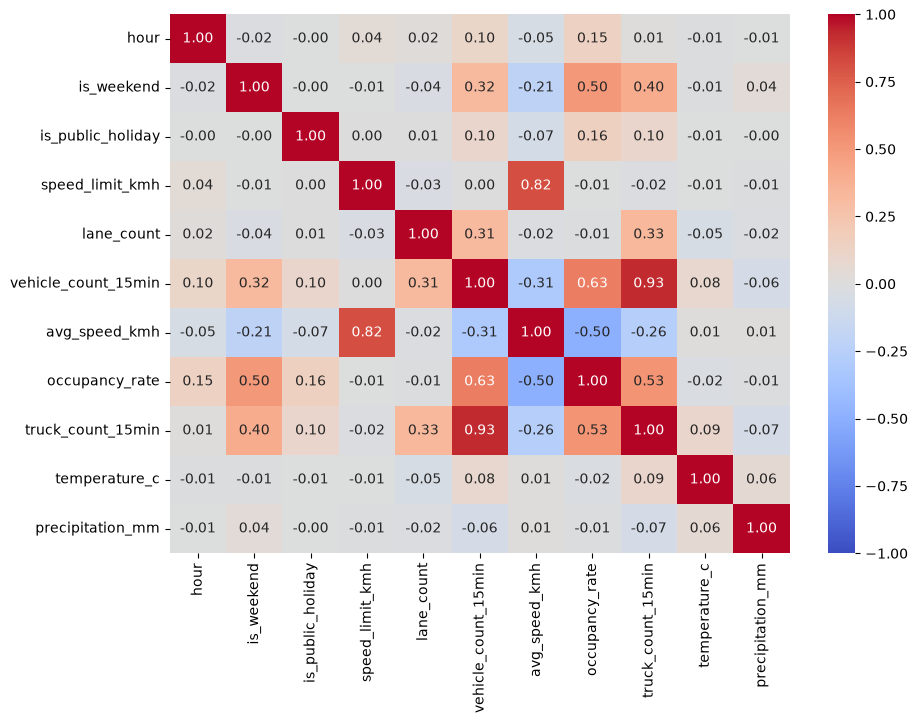

In [17]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
plt.show()

**Resultat:** Två par kolumner hänger starkt,

Antal lastbilar och antal fordon (0,93): När det är mycket trafik är det också fler lastbilar.
Hastighetsgräns och medelhastighet (0,82): På vägar där man får köra fort kör man också fortare.

Kolumnerna i varje par visar alltså nästan samma sak. Temperatur och nederbörd hänger inte ihop med någon annan kolumn (värden nära 0).

Trafikklassen vi vill förutsäga syns inte i heatmapen, eftersom den är text och inte siffror. Därför undersöker vi den i nästa steg.

## Medelhastighet per trafikklass
**Fråga:** Skiljer sig avg_speed_kmh mellan trafikklasserna 60 minuter fram?

**Varför:** Heatmapen visar bara hur siffer-kolumner hänger ihop med varandra. Målet är text och syns inte där. Därför jämför vi medelvärdet per klass: om det skiljer sig mellan klasserna kan kolumnen hjälpa modellen.

In [18]:
df.groupby('future_congestion_level')['avg_speed_kmh'].mean()

future_congestion_level
free_flow    61.552980
heavy        41.743617
light        49.280247
moderate     47.249639
Name: avg_speed_kmh, dtype: float64

**Resultat:** free_flow (62 km/h) och heavy (42 km/h) skiljer sig tydligt i medelhastighet, light (49) och moderate (47) knappt. Hastigheten är en användbar feature, främst för att skilja free_flow från heavy.

## Det vi har visat
- **Målet:** trafikklassen 60 minuter fram (future_congestion_level). Free_flow är vanligast (47,3 %), så baslinjen att slå är 47,3 %.
- **Timme:** heavy toppar kl. 7–8 och 16–17, så hour separerar klasserna tydligt.
- **Väder:** de flesta väder liknar totalen, så vädret är en svagare feature.
- **Samband:** truck_count och vehicle_count (0,93) samt speed_limit och avg_speed (0,82) hänger starkt ihop.
- **Hastighet:** free_flow (62 km/h) och heavy (42 km/h) skiljer sig tydligt, så hastigheten är en användbar feature.

## Trafikklass nu jämfört med 60 minuter fram
**Fråga:** Hur ofta är trafikklassen densamma nu som 60 minuter senare?

**Varför:** Den mest naturliga mänskliga gissningen är "om en timme är det som nu". Om klassen sällan ändras blir den gissningen svår att slå, och då är det den vår modell egentligen ska jämföras med, inte bara 47,3 %(att alltid gissa free_flow).

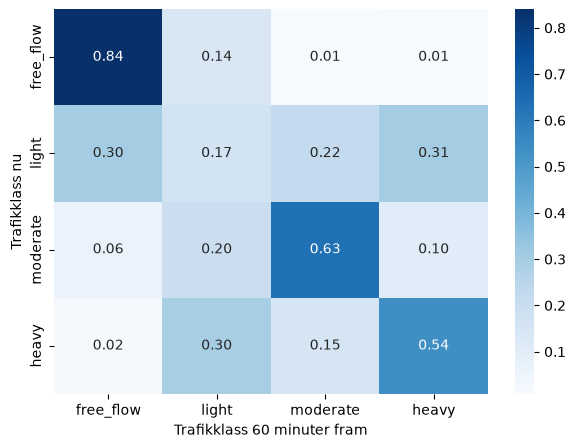

In [19]:
transitions = pd.crosstab(df['congestion_level'], df['future_congestion_level'], normalize='index')
transitions = transitions.reindex(index=levels, columns=levels)

plt.figure(figsize=(7, 5))
sns.heatmap(transitions, annot=True, fmt='.2f', cmap='Blues')
plt.xlabel('Trafikklass 60 minuter fram')
plt.ylabel('Trafikklass nu')
plt.show()

**Resultat:** Diagonalen visar hur ofta trafiken är densamma nu och om en timme. Fritt fram (free_flow) är mest stabilt: 84 % är fortfarande fritt fram en timme senare. Moderate (63 %) och heavy (54 %) är också ganska stabila.

Light är det stora undantaget. Bara 17 % är kvar i light, och resten blir lika ofta fritt fram (30 %) som kö (31 %). Light är alltså ett mellanläge, antingen på väg in i eller ut ur en rusning. Stora hopp är ovanliga: fritt fram blir nästan aldrig kö på en timme (1 %).

Människans gissning “det blir som nu” fungerar alltså bra för free_flow men dåligt för light. Det är där vår modell har störst chans att göra en bättre gissning, till exempel genom att använda klockslaget för att avgöra om rusningen börjar eller slutar.

## Förbereda data för modellen
**Fråga:** Hur gör vi om datan så att modellen kan använda den?

**Varför:** Modellen kan bara räkna med siffror, så textkolumnerna görs om med one-hot encoding: en ny kolumn per kategori med True/False.

Nuvarande trafikklass (congestion_level) görs också om med one-hot encoding, inte till 0–3. Siffrorna 0–3 skulle påstå att steget mellan free_flow och light är lika stort som mellan moderate och heavy. Data visar att det inte stämmer: medelhastigheten sjunker 13 km/h mellan free_flow och light, men bara 2 km/h mellan light och moderate.

Vi delar upp i 80 % träningsdata och 20 % testdata. `stratify` gör att varje klass finns i samma andel i båda delarna, vilket är viktigt när vi har så få rader.

In [20]:
text_columns = ['day_of_week', 'season', 'road_type', 'weather_condition', 'incident_type', 'congestion_level']

X = pd.get_dummies(df.drop(columns=['future_congestion_level']), columns=text_columns, drop_first=True)
y = df['future_congestion_level']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Träning:', len(X_train), 'rader, test:', len(X_test), 'rader')

Träning: 1816 rader, test: 454 rader


## Baslinje 1: gissa alltid den vanligaste klassen
**Fråga:** Vad får man om man alltid gissar free_flow?

**Varför:** Det är den sämsta "strategin" som ändå får poäng. En modell som inte slår den har inte lärt sig något.

In [21]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
acc_most_frequent = accuracy_score(y_test, baseline.predict(X_test))
acc_most_frequent

0.473568281938326

**Resultat:** 47,3 %

## Baslinje 2: människans gissning
**Fråga:** Hur ofta har man rätt om man gissar att trafiken om en timme blir som nu?

**Varför:** Det är så en pendlare eller trafikledare skulle gissa utan maskininlärning. Uppgiften säger att ML ska göra en bättre "chansning" än en människa, så det är den här baslinjen som verkligen räknas.

In [22]:
human_guess = df.loc[X_test.index, 'congestion_level']
acc_human = accuracy_score(y_test, human_guess)
acc_human

0.6365638766519823

**Resultat:** 63,7%

## Jämföra algoritmer
**Fråga:** Vilken algoritm passar bäst för problemet?

**Varför:** Algoritmerna fungerar på olika sätt, och vi vill förstå vilket sätt som passar trafikdata:
- **Logistisk regression** ser bara raka samband. Logistisk regression kan bara lära sig “senare på dagen = mer kö” eller “senare på dagen = mindre kö”. Den kan inte förstå att kön kommer, går och kommer tillbaka.
- **Beslutsträd** Ett beslutsträd ställer ja/nej-frågor i tur och ordning:
Det kan alltså lära sig att kö händer i vissa intervall, till exempel kl. 7–8 och kl. 16–17. Därför passar det trafikdata, som har just sådana toppar och gränser.
- **Random forest** är många beslutsträd som röstar, vilket brukar ge stabilare gissningar än ett ensamt träd.

Logistisk regression behöver att alla siffror ligger på samma skala (vehicle_count går upp till 2 685, occupancy_rate under 1), StandardScaler räknar därför om alla kolumner så att de ligger på samma skala, ungefär som att omvandla både kronor och dollar till samma valuta innan man jämför.
Träd bryr sig inte om det. De frågar bara “är värdet större än X?”, och den frågan fungerar lika bra oavsett om X är 0,3 eller 300.

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train)
acc_logreg = accuracy_score(y_test, logreg.predict(X_test_scaled))
acc_logreg

0.7048458149779736

In [24]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
acc_tree = accuracy_score(y_test, tree.predict(X_test))
acc_tree

0.7158590308370044

In [25]:
forest = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
acc_forest = accuracy_score(y_test, forest.predict(X_test))
acc_forest

0.8149779735682819

**Resultat:** Random forest fick högst accuracy (81,5 %), följt av beslutsträdet (71,6 %) och logistisk regression (70,5 %). Människans gissning “det blir som nu” gav 63,7 %.

Att random forest vann stämmer med vad vi trodde utifrån hour-grafen: träd kan fånga att kö kommer i toppar under dygnet. Det enskilda beslutsträdet var bara något bättre än logistisk regression, troligen för att det bara får ställa tre frågor (max_depth=3). Det räcker inte för att fånga både morgon- och kvällsrusningen. Logistisk regression klarade sig bättre än väntat, troligen för att flera viktiga ledtrådar är raka samband: högre beläggning och lägre hastighet betyder mer kö.

Random forest består av 100 träd som kan ställa många frågor och röstar om svaret. Därför går vi vidare med random forest i optimeringarna.

Random forest slår alltså människans gissning med 17,8 procentenheter.

## Vilka klasser blandar modellen ihop?
**Fråga:** Var gör den bästa modellen fel?

**Varför:** Accuracy visar bara hur ofta modellen har rätt, inte *hur* den har fel. Att gissa free_flow när det blir heavy är ett mycket värre fel än att blanda ihop light och moderate. Medelhastigheten visade dessutom att light och moderate är svåra att skilja åt.

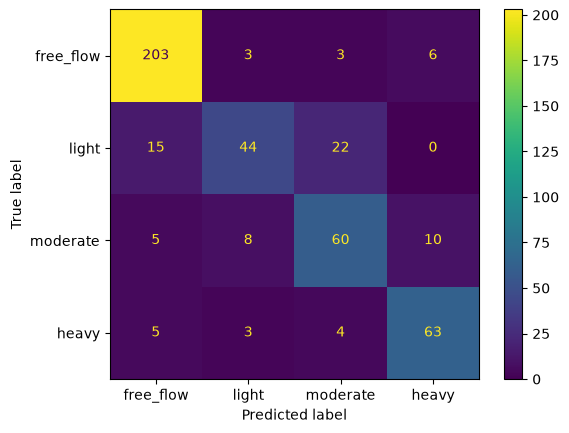

In [26]:
ConfusionMatrixDisplay.from_predictions(y_test, forest.predict(X_test), labels=levels)
plt.show()

**Resultat:** Modellen är bäst på free_flow (203 av 215 rätt, 94 %) och heavy (63 av 75, 84 %), men sämst på light (44 av 81, 54 %).

Light blandas oftast ihop med moderate (22 gånger). Totalt blandas light och moderate ihop 30 gånger, vilket stämmer med att de hade nästan samma medelhastighet (49 och 47 km/h).

Modellen gör 84 fel av 454. De flesta felen är små: 62 av dem (ca 74 %) hamnar bara ett steg fel, till exempel light i stället för moderate. Allvarliga fel, där modellen säger fritt fram när det blir kö eller tvärtom, händer bara 11 gånger (ca 2 % av alla gissningar).

Light är svårast även för modellen, men den klarar det mycket bättre än människan. Gissningen “det blir som nu” hade bara rätt i 17 % av fallen när det var light, medan modellen har rätt i 54 %. Det är här modellen gör störst skillnad jämfört med en människa (17 % gäller när det är light nu, medan 54 % gäller när det blir light om en timme. Det är inte exakt samma sak, men båda visar att light är svårast att förutsäga och vår modell klarar det bättre).

# Optimeringar
Varje optimering bygger på något vi såg i graferna. Optimeringarna är hypotetiska förbättringar: de är välgrundade, men med bara några hundra testrader kan slumpen göra att resultatet ibland blir sämre. Vi jämför alltid med random forest ovan.

## Optimering 1: hastighet i förhållande till hastighetsgränsen
**Fråga:** Kan vi göra hastigheten mer användbar för modellen?

**Varför:** Heatmapen visade att avg_speed_kmh och speed_limit_kmh hänger ihop (0,82). Hastigheten beror alltså mycket på vilken väg det är. 50 km/h är kö på en motorväg men fritt flöde i stan. Om vi delar hastigheten med hastighetsgränsen får vi ett mått på hur trögt det går oavsett väg: 1,0 betyder att trafiken går i full fart, 0,4 att den går i 40 % av tillåten fart.

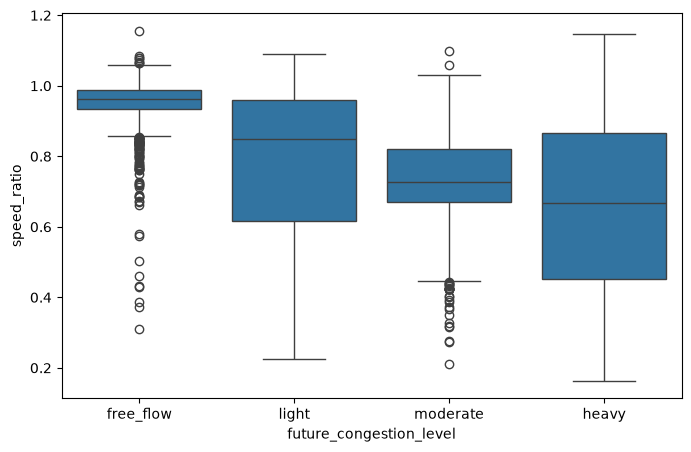

In [27]:
df['speed_ratio'] = df['avg_speed_kmh'] / df['speed_limit_kmh']

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='future_congestion_level', y='speed_ratio', order=levels)
plt.show()

**Resultat graf:** Medianerna sjunker i rätt ordning: free_flow (ca 0,96), light (ca 0,85), moderate (ca 0,73) och heavy (ca 0,67). Ju mer kö det blir om en timme, desto långsammare går trafiken redan nu jämfört med hastighetsgränsen.

free_flow skiljer sig tydligt från de andra klasserna. Light och moderate skiljer sig tydligare åt här än med bara avg_speed_kmh: medianerna är 0,85 och 0,73, jämfört med 49 och 47 km/h tidigare.

Lådorna överlappar ändå, särskilt för light och heavy. Det beror på att hastigheten mäts nu medan klassen gäller om en timme, och trafiken hinner ändras. Speed_ratio verkar alltså vara en bättre ledtråd än avg_speed_kmh, men den räcker ändå inte ensam, eftersom lådorna överlappar. Ett värde som 0,7 kan bli light, moderate eller heavy om en timme. Hastigheten visar hur trafiken är nu, men inte vart den är på väg. Där behövs andra ledtrådar, till exempel klockslaget: samma hastighet kl. 07 en vardag betyder troligen kö om en timme, men kl. 13 troligen fritt fram. Därför låter vi modellen använda speed_ratio tillsammans med de andra kolumnerna.

In [28]:
X = pd.get_dummies(df.drop(columns=['future_congestion_level']), columns=text_columns, drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

forest_ratio = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
acc_opt1 = accuracy_score(y_test, forest_ratio.predict(X_test))
acc_opt1

0.8215859030837004

**Resultat:** Med speed_ratio fick random forest 82,2 % rätt, jämfört med 81,5 % utan. Det är en förbättring på 0,7 procentenheter, vilket motsvarar 3 fler rätta gissningar av 454.

Förbättringen går i den riktning vi förväntade oss, eftersom speed_ratio skilde klasserna tydligare åt i grafen. Skillnaden är dock liten, och med så få testrader kan den delvis bero på slumpen. En förklaring till att den inte blev större är att modellen redan hade både avg_speed_kmh och speed_limit_kmh, och random forest kan själv kombinera dem. Speed_ratio gör det sambandet lättare att hitta, men ger inte helt ny information.

## Optimering 2: ta bort kolumner som säger samma sak
**Fråga:** Blir modellen bättre om vi tar bort truck_count_15min?

**Varför:** Heatmapen visade att truck_count_15min och vehicle_count_15min hänger ihop mycket starkt (0,93). Lastbilarna ingår dessutom i det totala antalet fordon. En kolumn som nästan bara upprepar en annan ger modellen mer brus än ny information.

In [29]:
X_train_opt2 = X_train.drop(columns=['truck_count_15min'])
X_test_opt2 = X_test.drop(columns=['truck_count_15min'])

forest_opt2 = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_opt2, y_train)
acc_opt2 = accuracy_score(y_test, forest_opt2.predict(X_test_opt2))
acc_opt2

0.8127753303964758

**Resultat:** Utan truck_count_15min fick modellen 81,3 % rätt, jämfört med 82,2 % med den (optimering 1). Det blev alltså något sämre, med 4 färre rätta gissningar av 454.

Vår hypotes var att kolumnen bara upprepade vehicle_count_15min, men resultatet tyder på att den ändå bar lite egen information. Ett samband på 0,93 betyder att kolumnerna liknar varandra, inte att de är identiska. Andelen lastbilar kan till exempel skilja sig mellan vägtyper och tider på dygnet. Random forest klarar dessutom kolumner som liknar varandra ganska bra, så det fanns lite att vinna på att ta bort den. Skillnaden är liten och kan delvis bero på slumpen. Vi behåller därför truck_count_15min.

## Optimering 3: hur djupa ska träden vara?
**Fråga:** Vilket maxdjup ger bäst resultat?

**Varför:** Ett för grunt träd missar mönster. Ett för djupt träd lär sig träningsdatan utantill och blir sämre på ny data, och med så få rader är risken för det stor. Vi testar olika djup på en valideringsmängd från träningsdatan, så att testdatan bara används till slutresultatet. Där linjerna börjar gå isär börjar modellen lära sig utantill.

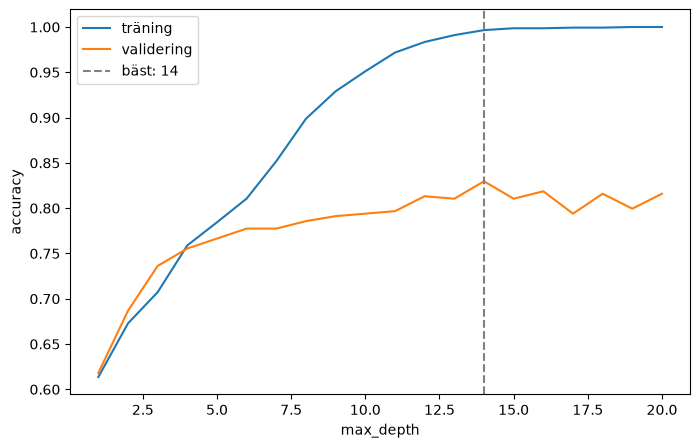

In [30]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)
depths = range(1, 21)
train_scores = []
val_scores = []

for depth in depths:
    model = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42).fit(X_tr, y_tr)
    train_scores.append(accuracy_score(y_tr, model.predict(X_tr)))
    val_scores.append(accuracy_score(y_val, model.predict(X_val)))

best_depth = list(depths)[val_scores.index(max(val_scores))]

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, label='träning')
plt.plot(depths, val_scores, label='validering')
plt.axvline(best_depth, color='grey', linestyle='--', label=f'bäst: {best_depth}')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.legend()
plt.show()

In [31]:
forest_opt3 = RandomForestClassifier(n_estimators=100, max_depth=best_depth, random_state=42).fit(X_train, y_train)
acc_opt3 = accuracy_score(y_test, forest_opt3.predict(X_test))
acc_opt3

0.8061674008810573

**Resultat:** Upp till djup 4 följer träning och validering varandra, vilket betyder att modellen lär sig riktiga mönster. Efter det går linjerna isär: träningen når nästan 100 % runt djup 14, där modellen lär sig träningsdatan utantill. Valideringen planar ändå ut runt 80 % och blir inte tydligt sämre, eftersom random forest låter många träd rösta så att deras misstag tar ut varandra.

Bästa djup på valideringen var 14 (ca 83 %), men valideringskurvan hoppar upp och ner mellan 79 och 83 % efter djup 12. Toppen vid 14 beror alltså troligen delvis på slumpen. På testdatan gav djup 14 80,6 %, sämre än optimering 1 utan djupgräns (82,2 %). Optimeringen var välgrundad, men med så få rader kan slumpen göra att ett val som ser bäst ut på valideringen inte håller på ny data. Vi behåller därför modellen från optimering 1, utan djupgräns, som vår slutliga modell.

# Sammanställning
**Fråga:** Slog maskininlärningen människans gissning, och vilka steg hjälpte?

**Varför:** Alla resultat i en graf gör det lätt att se förbättringarna steg för steg. Den röda linjen är människans gissning.

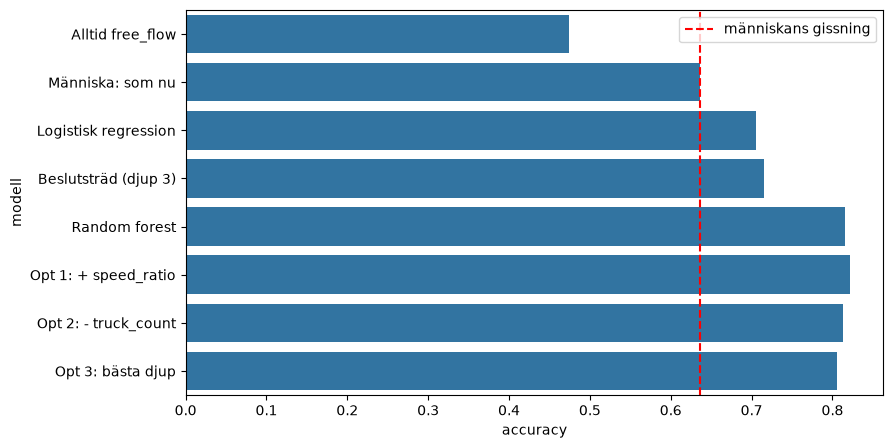

,modell,accuracy
0,Alltid free_flow,0.473568
1,Människa: som nu,0.636564
2,Logistisk regression,0.704846
3,Beslutsträd (djup 3),0.715859
4,Random forest,0.814978
5,Opt 1: + speed_ratio,0.821586
6,Opt 2: - truck_count,0.812775
7,Opt 3: bästa djup,0.806167


In [32]:
results = pd.DataFrame({
    'modell': ['Alltid free_flow', 'Människa: som nu', 'Logistisk regression', 'Beslutsträd (djup 3)',
               'Random forest', 'Opt 1: + speed_ratio', 'Opt 2: - truck_count', 'Opt 3: bästa djup'],
    'accuracy': [acc_most_frequent, acc_human, acc_logreg, acc_tree,
                 acc_forest, acc_opt1, acc_opt2, acc_opt3],
})

plt.figure(figsize=(9, 5))
sns.barplot(data=results, x='accuracy', y='modell')
plt.axvline(acc_human, color='red', linestyle='--', label='människans gissning')
plt.legend()
plt.show()

results

**Resultat:** Alla modeller slår båda baslinjerna. Människans gissning “det blir som nu” (63,7 %) är redan mycket bättre än att alltid gissa free_flow (47,4 %), men alla tre algoritmerna är bättre än människan.

Random forest är klart bäst bland algoritmerna (81,5 %), cirka 10 procentenheter före logistisk regression (70,5 %) och beslutsträdet (71,6 %). Av optimeringarna gav bara speed_ratio en förbättring (82,2 %). Att ta bort truck_count (81,3 %) och begränsa trädens djup (80,6 %) gav något sämre resultat.

# Slutsats
- **Slog vi människan?** Ja. Vår bästa modell, random forest med speed_ratio, har rätt i 82,2 % av fallen, jämfört med 63,7 % för människans gissning. Det är 18,5 procentenheter bättre, eller cirka 84 fler rätta gissningar av 454. Skillnaden spelar roll i praktiken: modellen är framför allt bättre på light, där trafiken ofta ändras inom en timme och “det blir som nu” sällan stämmer.
- **Bästa algoritmen:** Random forest. Trafiken har toppar under dygnet och tydliga gränser, till exempel rusningstid och låg hastighet, och sådana samband fångar beslutsträd bättre än logistisk regression, som bara ser raka samband. Random forest låter dessutom 100 träd rösta, vilket gör gissningarna stabilare än ett ensamt träd.
- **Optimeringarna:** Speed_ratio hjälpte mest (+0,7 procentenheter), eftersom den visar hur trögt det går oavsett vägtyp. De två andra optimeringarna var välgrundade men blev något sämre. Truck_count bar troligen lite egen information trots det starka sambandet med vehicle_count, och det bästa djupet på valideringen var troligen delvis tur. Alla skillnader mellan optimeringarna är små, högst 1,5 procentenheter eller några få gissningar, och kan delvis bero på slumpen.
- **Begränsningar:** bara ca 1 % av de 200 000 raderna hade en mätning exakt 60 minuter senare, så vi har lite data och få testrader.